# Bounds isolation check

The repaired pipeline fits much better than the earlier (v2) one: the stage-0 objective drops from about 60 to about 12. Is that a better model or a different box? This notebook isolates how much of the drop each of the three bound changes explains, with a full $2^3$ factorial over

| factor | v2 setting | v3 setting |
|---|---|---|
| **M** balanced-metabolite bounds | log-normal box with $n_\text{std} = 2$ (excluded six measured values) | $n_\text{std} = 3$ (contains all data) |
| **D** free-drain bounds | mean $\pm 2$ sd of the data | data range $\pm 10\%$ of the span |
| **P** C$_\text{Pi}$ bounds | pooled cofactor range $(10^{-6}, 2.728)$ mM | literature $(1, 20)$ mM |

All 37 parameters free, same data, theta bounds and IPOPT options for every cell. Per cell the best of three candidates is kept, each refined with the tight options: (A) the v2 stage-0 anchor primal point, (B) the v3 stage-0 anchor primal point, (C) the best of a recorded multistart warm started at the v2 theta.

**Attribution.** Let $f(\text{cell})$ be the objective of a cell. For factor $k$: *one at a time from v2* is $f(\text{all v2}) - f(\text{only } k \text{ at v3})$, *remove one from v3* is $f(\text{all v3 except } k) - f(\text{all v3})$, and the **Shapley share** averages the marginal gain of $k$ over all orders in which the three factors can be switched,

$$ \phi_k \;=\; \sum_{S \subseteq \{M,D,P\}\setminus\{k\}} \frac{|S|!\,(3 - |S| - 1)!}{3!}\,\big[f(S) - f(S \cup \{k\})\big]. $$

The shares add up to the total drop, which is why the Shapley column is used in the text.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import check_out_dir, resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.RUN["out_dir"])   # default: out_dir of settings/run.csv; relative paths are relative to the repo root
RUN = os.environ.get("HK_RUN", "0") == "1"

try:
    check_out_dir(OUT)
    WRITABLE = True
except ValueError:
    WRITABLE = False

if RUN and not WRITABLE:
    raise ValueError("HK_RUN=1 refuses an output directory inside results/, results_v2/ or results_v3/: %s" % OUT)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)
print("RUN      :", RUN, "(False = load the saved results of OUT; True = compute and save into OUT)")
print("WRITABLE :", WRITABLE, "(tables / figures / report are written to OUT only if True)")

import json
import math
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from settings import SOLVER_OPTIONS, TIGHT_OPTIONS, RUN as RUN_SETTINGS, default_params
from model.parameters import ALL_PARAMS, FREE_DRAIN_KEYS
from estimation.estimator import GlycolysisParameterEstimator
from estimation.anchors import check_bounds, read_anchor
from estimation.multistart import multistart_recorded
from data import metabolite_bounds, variable_bounds, available_conditions
from progress import log

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

ISO = os.path.join(OUT, "isolation")
N_JOBS = int(os.environ.get("HK_N_JOBS", RUN_SETTINGS["n_jobs"]))
V2_STAGE0 = os.path.join(REPO, RUN_SETTINGS["stage0_warm_start"])

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model
RUN      : True (False = load the saved results of OUT; True = compute and save into OUT)
WRITABLE : True (tables / figures / report are written to OUT only if True)


## 1. The bound options of the factorial

The v2 options are rebuilt from the data (`metabolite_bounds` with $n_\text{std}=2$, drains mean $\pm 2$ sd); the v3 options are those of `variable_bounds()` (settings/bounds_rules.csv).

In [2]:
U_V3, X_V3, DRAIN_V3 = variable_bounds()
U_V2, X_V2 = metabolite_bounds(n_std=2)

needs = pd.read_csv(os.path.join(REPO, "Data", "cellular_needs.csv"), index_col=0)
DRAIN_V2 = {}
for key in FREE_DRAIN_KEYS:
    row = needs.loc[key].astype(float)
    DRAIN_V2[key] = (float(row.mean()) - 2.0 * float(row.std(ddof=1)), float(row.mean()) + 2.0 * float(row.std(ddof=1)))

X_OPT = {"v2": X_V2, "v3": X_V3}
D_OPT = {"v2": DRAIN_V2, "v3": DRAIN_V3}
P_OPT = {"v2": tuple(U_V2["C_pi"]), "v3": tuple(U_V3["C_pi"])}

pd.DataFrame({"C_pi bounds": P_OPT, "C_g6p bounds": {k: X_OPT[k]["C_g6p"] for k in X_OPT},
              "g6p drain bounds": {k: D_OPT[k]["C_g6p"] for k in D_OPT}})

,C_pi bounds,C_g6p bounds,g6p drain bounds
v2,"(0.000001, 2.728)","(0.051849, 0.743803)","(-0.535184, 2.014066)"
v3,"(1.0, 20.0)","(0.026642, 1.447562)","(-0.24088, 3.00008)"


In [3]:
def make_cell_estimator(m, d, p, theta, x_init=None, u_init=None, b_init=None):
    """Estimator with all 37 parameters free and the bounds of the cell (m, d, p each 'v2' or 'v3')."""
    u_bounds = {**U_V3, "C_pi": P_OPT[p]}
    return GlycolysisParameterEstimator(conditions=available_conditions(), theta_init=dict(theta), x_bounds=X_OPT[m],
                                        u_bounds=u_bounds, drain_bounds=D_OPT[d], solver_options=dict(SOLVER_OPTIONS),
                                        x_init=x_init, u_init=u_init, b_init=b_init)

def refined(est):
    """Solve and refine with the tight options."""
    est.estimate()
    est.refine_anchor(primary_options=dict(TIGHT_OPTIONS))
    return est

## 2. Run (`HK_RUN=1`)

8 cells, each with three candidate fits and a recorded multistart: the longest computation of the analysis notebooks. It needs the v2 stage-0 anchor named in `settings/run.csv` (`stage0_warm_start`, read only) and `OUT/stage0/anchor_state.pkl`. Writes `isolation_cells.csv`, `isolation_breakdown_by_condition.csv`, `isolation_attribution.csv` and `isolation_summary.json` into `OUT/isolation/`. The settings are the dict `params` below (defaults from `settings/run.csv`); switch: `HK_N_JOBS`.

In [4]:
# Settings of the isolation check (defaults from settings/run.csv)
params = default_params("isolation")
params["isolation_n_starts"] = 30   # random starts of the multistart in every cell
params["n_jobs"] = N_JOBS           # worker processes (HK_N_JOBS)
params

{'n_jobs': 8, 'isolation_n_starts': 30}

In [5]:
if RUN:
    os.makedirs(ISO, exist_ok=True)
    check_bounds()
    anchors = {"v2_anchor": read_anchor(V2_STAGE0), "v3_anchor": read_anchor(os.path.join(OUT, "stage0"))}
    theta_v2 = {p: float(anchors["v2_anchor"]["theta"][p]) for p in ALL_PARAMS}
    rows, breakdowns = [], {}
    for m, d, p in itertools.product(("v2", "v3"), repeat=3):
        cell = "M%s_D%s_P%s" % (m[1], d[1], p[1])
        cands = {}
        for name, st in anchors.items():
            theta = {q: float(st["theta"][q]) for q in ALL_PARAMS}
            try:
                cands[name] = refined(make_cell_estimator(m, d, p, theta, x_init=st["x_init"], u_init=st["u_init"], b_init=st["b_init"]))
            except Exception as exc:   # noqa: BLE001
                log("%s %s failed: %s" % (cell, name, str(exc)[:120]))
        table = multistart_recorded(make_cell_estimator(m, d, p, theta_v2), params["isolation_n_starts"], 0, params["n_jobs"])
        conv = table[table["converged"]].sort_values("obj_value")
        if len(conv):
            best = conv.iloc[0]
            try:
                cands["multistart"] = refined(make_cell_estimator(m, d, p, {**theta_v2, **{q: float(best["init_" + q]) for q in ALL_PARAMS}}))
            except Exception as exc:   # noqa: BLE001
                log("%s multistart re-run failed: %s" % (cell, str(exc)[:120]))
        objs = {k: float(v.obj_value) for k, v in cands.items()}
        used = min(objs, key=objs.get)
        bd = cands[used].objective_breakdown()
        breakdowns[cell] = bd["total"]
        rows.append({"cell": cell, "M": m, "D": d, "P": p, "obj": objs[used], "used": used, **{"obj_" + k: v for k, v in objs.items()},
                     "ms_n_converged": int(len(conv)), "ms_best_table": float(conv["obj_value"].min()) if len(conv) else np.nan,
                     "flux_wsse_mean": float(bd.loc["MEAN", "flux_wsse"]), "met_wsse_mean": float(bd.loc["MEAN", "met_wsse"]),
                     "KO18_total": float(bd.loc["KO18", "total"]), "KO10_total": float(bd.loc["KO10", "total"]),
                     "KO05_total": float(bd.loc["KO05", "total"])})
        log("%s: obj %.4f (%s) %s" % (cell, rows[-1]["obj"], used, {k: round(v, 3) for k, v in objs.items()}))
        pd.DataFrame(rows).to_csv(os.path.join(ISO, "isolation_cells.csv"), index=False)
        pd.DataFrame(breakdowns).to_csv(os.path.join(ISO, "isolation_breakdown_by_condition.csv"))
else:
    print("RUN is False: the isolation check is loaded from", ISO)

[     1s] check_bounds_contain_data: OK (balanced, cofactors, drains); Pi bounds (1.0, 20.0)


[   114s] M2_D2_P2: obj 55.4589 (v3_anchor) {'v2_anchor': 83.101, 'v3_anchor': 55.459, 'multistart': 65.651}


[   248s] M2_D2_P3: obj 50.5775 (v3_anchor) {'v2_anchor': 82.236, 'v3_anchor': 50.578, 'multistart': 50.593}


[   331s] M2_D3_P2: obj 53.5499 (v3_anchor) {'v2_anchor': 58.761, 'v3_anchor': 53.55, 'multistart': 55.194}


[   459s] M2_D3_P3: obj 51.4996 (v3_anchor) {'v2_anchor': 76.931, 'v3_anchor': 51.5, 'multistart': 54.071}


[   644s] M3_D2_P2: obj 13.5527 (multistart) {'v2_anchor': 63.711, 'v3_anchor': 14.729, 'multistart': 13.553}


[   765s] M3_D2_P3: obj 11.2047 (v3_anchor) {'v2_anchor': 16.275, 'v3_anchor': 11.205, 'multistart': 13.043}


[   883s] M3_D3_P2: obj 13.3569 (multistart) {'v2_anchor': 17.7, 'v3_anchor': 14.049, 'multistart': 13.357}


[   965s] M3_D3_P3: obj 11.7455 (multistart) {'v2_anchor': 15.127, 'v3_anchor': 64.027, 'multistart': 11.745}


## 3. Attribution of the drop

Computed from the objectives of the 8 cells (`isolation_cells.csv`); with `HK_RUN=1` it is written to `isolation_attribution.csv` and `isolation_summary.json`.

In [6]:
FACTORS = ("M", "D", "P")

def objective_of(objectives, switched):
    """Objective of the cell where the factors in ``switched`` are at v3 and the others at v2."""
    return float(objectives[tuple("v3" if k in switched else "v2" for k in FACTORS)])

def shapley_share(objectives, factor):
    """Marginal gain of switching ``factor`` to v3, averaged over all orders of switching the three factors."""
    others = [o for o in FACTORS if o != factor]
    share = 0.0
    for r in range(len(others) + 1):
        for subset in itertools.combinations(others, r):
            weight = math.factorial(r) * math.factorial(len(FACTORS) - r - 1) / math.factorial(len(FACTORS))
            share += weight * (objective_of(objectives, set(subset)) - objective_of(objectives, set(subset) | {factor}))
    return share

cells_path = os.path.join(ISO, "isolation_cells.csv")
cells = pd.read_csv(cells_path) if os.path.exists(cells_path) else None
if cells is not None and len(cells) == 8:
    objectives = cells.set_index(["M", "D", "P"])["obj"]
    all_v2 = objective_of(objectives, set())
    all_v3 = objective_of(objectives, set(FACTORS))
    one_at_a_time = {}
    remove_one = {}
    shapley = {}
    for k in FACTORS:
        one_at_a_time[k] = all_v2 - objective_of(objectives, {k})
        remove_one[k] = objective_of(objectives, {o for o in FACTORS if o != k}) - all_v3
        shapley[k] = shapley_share(objectives, k)
    attribution = pd.DataFrame({"from_v2_one_at_a_time": one_at_a_time, "from_v3_remove_one": remove_one,
                                "shapley": shapley})
    attribution.loc["total"] = [all_v2 - all_v3] * 3
    if RUN:
        attribution.to_csv(os.path.join(ISO, "isolation_attribution.csv"))
        json.dump({"obj_all_v2": all_v2, "obj_all_v3": all_v3, "shapley": shapley},
                  open(os.path.join(ISO, "isolation_summary.json"), "w"), indent=1)
    print("objective with all v2 bounds %.3f, all v3 bounds %.3f" % (all_v2, all_v3))
    display(attribution)
else:
    attribution = None
    print("isolation_cells.csv with 8 cells not found: run the isolation check first")

objective with all v2 bounds 55.459, all v3 bounds 11.745


,from_v2_one_at_a_time,from_v3_remove_one,shapley
M,41.906182,39.754110,40.481053
D,1.908986,-0.540754,0.335023
P,4.881360,1.611449,2.897312
total,43.713388,43.713388,43.713388


In [7]:
cells

,cell,M,D,P,obj,used,obj_v2_anchor,obj_v3_anchor,obj_multistart,ms_n_converged,ms_best_table,flux_wsse_mean,met_wsse_mean,KO18_total,KO10_total,KO05_total
0,M2_D2_P2,v2,v2,v2,55.458871,v3_anchor,83.100816,55.458871,65.651123,28,66.209887,1.321372,54.132704,1025.781968,0.758336,45.834337
1,M2_D2_P3,v2,v2,v3,50.577511,v3_anchor,82.236029,50.577511,50.592957,29,50.818022,1.216162,49.360336,1000.868065,0.309939,37.456735
2,M2_D3_P2,v2,v3,v2,53.549885,v3_anchor,58.761064,53.549885,55.194309,27,56.606099,1.035315,52.513690,1001.133803,0.725879,41.906705
3,M2_D3_P3,v2,v3,v3,51.499593,v3_anchor,76.931259,51.499593,54.070586,30,54.396683,1.476893,50.016549,1018.788935,0.664269,35.804852
4,M3_D2_P2,v3,v2,v2,13.552689,multistart,63.711239,14.729407,13.552689,28,16.729607,1.090773,12.460947,134.798422,0.349415,44.075010
5,M3_D2_P3,v3,v2,v3,11.204729,v3_anchor,16.275453,11.204729,13.042993,28,13.066451,1.245093,9.953937,135.668142,0.302755,34.507599
6,M3_D3_P2,v3,v3,v2,13.356932,multistart,17.699608,14.049417,13.356932,28,17.714790,1.122546,12.233612,134.584968,0.549508,44.263944
7,M3_D3_P3,v3,v3,v3,11.745483,multistart,15.127089,64.027314,11.745483,29,12.324419,1.455799,10.276584,147.920107,0.519369,30.452215


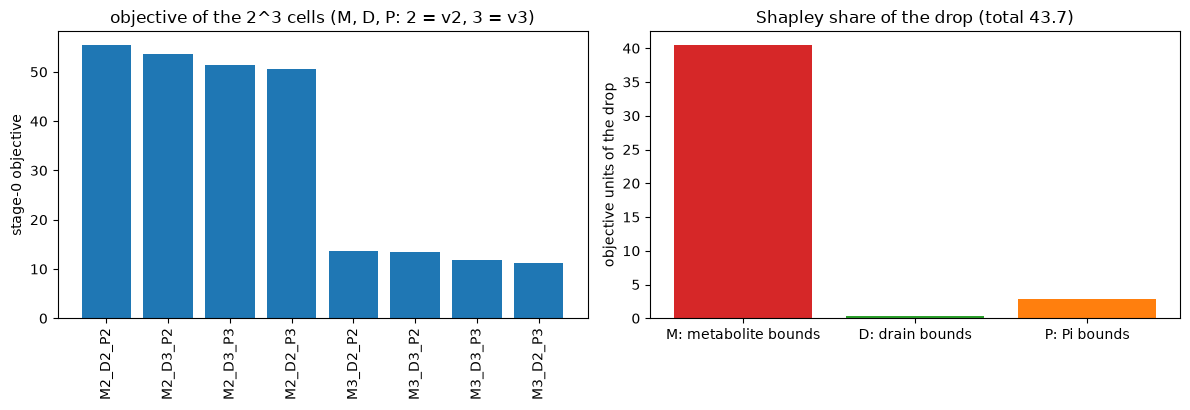

In [8]:
if cells is not None and attribution is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    ax_cells, ax_shap = axes

    # objective of the 8 cells
    order = cells.sort_values("obj", ascending=False)
    ax_cells.bar(range(len(order)), order["obj"], color="tab:blue")
    ax_cells.set_xticks(range(len(order)))
    ax_cells.set_xticklabels(order["cell"], rotation=90)
    ax_cells.set_ylabel("stage-0 objective")
    ax_cells.set_title("objective of the 2^3 cells (M, D, P: 2 = v2, 3 = v3)")

    # Shapley shares of the drop
    share = attribution.loc[["M", "D", "P"], "shapley"]
    ax_shap.bar(range(3), share.to_numpy(), color=["tab:red", "tab:green", "tab:orange"])
    ax_shap.set_xticks(range(3))
    ax_shap.set_xticklabels(["M: metabolite bounds", "D: drain bounds", "P: Pi bounds"])
    ax_shap.set_ylabel("objective units of the drop")
    ax_shap.set_title("Shapley share of the drop (total %.1f)" % attribution.loc["total", "shapley"])

    fig.tight_layout()
    plt.show()

### Where the objective lives

`isolation_breakdown_by_condition.csv`: the per-condition objective of every cell. In the saved run the total objective of KO18 was about 1026 in the all-v2 cell and about 135 once the box has $n_\text{std}=3$. That is why the improvement from v2 to v3 is mostly *the box containing the data*, not a better model.

In [9]:
breakdown_path = os.path.join(ISO, "isolation_breakdown_by_condition.csv")
if os.path.exists(breakdown_path):
    bd = pd.read_csv(breakdown_path, index_col=0)
    hard = bd.loc[[c for c in ("KO18", "KO10", "KO05") if c in bd.index]]
    display(hard)

,M2_D2_P2,M2_D2_P3,M2_D3_P2,M2_D3_P3,M3_D2_P2,M3_D2_P3,M3_D3_P2,M3_D3_P3
KO18,1025.781968,1000.868065,1001.133803,1018.788935,134.798422,135.668142,134.584968,147.920107
KO10,0.758336,0.309939,0.725879,0.664269,0.349415,0.302755,0.549508,0.519369
KO05,45.834337,37.456735,41.906705,35.804852,44.075010,34.507599,44.263944,30.452215
